# 06. A corrida pelo melhor filtro desta caixa, e o modelo de fundação (TabPFN)

**Corrida (experimento 04).** Os 10 melhores da busca genética + o padrão disputam em divisões novas
(sementes 201 e 202); o vencedor é **verificado** em outras divisões (203 e 204). Objetivo: o melhor filtro
*para esta caixa*, com o limiar de custo.

**TabPFN (experimento 05).** O TabPFN-3.5 é um modelo de fundação para tabelas: pré-treinado em milhões de
tabelas sintéticas, ele classifica uma tabela nova sem ajuste. Testamos sozinho e como 8ª família do stacking
(Stacking 8), na nuvem (3.5-Plus, 20 folds + base externa) e localmente em CPU (3.5-Fast, 5 divisões).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spamfilter import caminhos, graficos, saidas

C = pd.read_csv(caminhos.EXPERIMENTOS / "04_corrida" / "corrida.csv", sep=";", decimal=",")
corr = C.groupby(["etapa", "candidato"])[["mcc", "mcc_custo", "custo_por_mil"]].mean()
print(corr.round(4).to_string())

                                mcc  mcc_custo  custo_por_mil
etapa       candidato                                        
corrida     #1               0.9754     0.9662        39.0342
            #10              0.9751     0.9553        38.6777
            #2               0.9769     0.9597        39.7626
            #3               0.9760     0.9650        39.5179
            #4               0.9769     0.9597        39.7622
            #5 (GA exp. 03)  0.9760     0.9615        39.0364
            #6               0.9766     0.9627        38.5527
            #7               0.9760     0.9615        39.0364
            #8               0.9763     0.9650        37.5861
            #9               0.9765     0.9621        38.7947
            padrão           0.9735     0.9512        44.2325
verificação #1               0.9710     0.9612        36.2566
            #10              0.9736     0.9580        36.6173
            #2               0.9713     0.9615        37.1017
        

**Leitura.** Todos os candidatos empatam no MCC (platô): o Stacking 7 é pouco sensível a hiperparâmetros.
O primeiro colocado da corrida **não** se confirmou na verificação (maldição do vencedor de novo). Decisão (D8):
o filtro **Especialista** é a configuração do GA do experimento 03, definida antes da corrida, que custa
cerca de 12% menos que o padrão nesta caixa (36,6 contra 41,5 por mil e-mails).

In [2]:
T = caminhos.EXPERIMENTOS / "05_tabpfn"
T20 = pd.read_csv(T / "tabpfn_20folds.csv", sep=";", decimal=",")
TEX = pd.read_csv(T / "tabpfn_externo.csv", sep=";", decimal=",")
TLN = pd.read_csv(T / "tabpfn_local_x_nuvem.csv", sep=";", decimal=",")
t20 = T20.groupby("metodo")[["mcc", "pr_auc", "mcc_custo", "custo_por_mil"]].mean().sort_values("custo_por_mil")
tex = TEX.groupby("metodo")[["mcc", "pr_auc", "mcc_custo", "real_lixeira_custo", "spam_passou_custo", "custo_por_mil"]].mean().sort_values("custo_por_mil")
tln = TLN.groupby("metodo")[["mcc", "pr_auc", "custo_por_mil"]].mean()
print("== nesta caixa (20 folds) ==\n" + t20.round(4).to_string())
print("\n== caixas novas (Enron2-6) ==\n" + tex.round(4).to_string())
print("\n== local (3.5-Fast, CPU) × nuvem (3.5-Plus), 5 divisões ==\n" + tln.round(4).to_string())

== nesta caixa (20 folds) ==
                                      mcc  pr_auc  mcc_custo  custo_por_mil
metodo                                                                     
Stacking 7 especialista            0.9744  0.9976     0.9615        36.6179
Stacking 8 especialista (+TabPFN)  0.9747  0.9979     0.9572        37.8905
Stacking 8 padrão (+TabPFN)        0.9727  0.9978     0.9565        38.1916
Stacking 7 padrão                  0.9734  0.9973     0.9554        41.5130
LinearSVC otimizado                0.9627  0.9956     0.9406        50.0340
TabPFN-3.5-Plus                    0.9625  0.9965     0.9224        55.5944

== caixas novas (Enron2-6) ==
                                      mcc  pr_auc  mcc_custo  real_lixeira_custo  spam_passou_custo  custo_por_mil
metodo                                                                                                            
TabPFN-3.5-Plus                    0.8812  0.9867     0.8031              0.0086             0.1663   

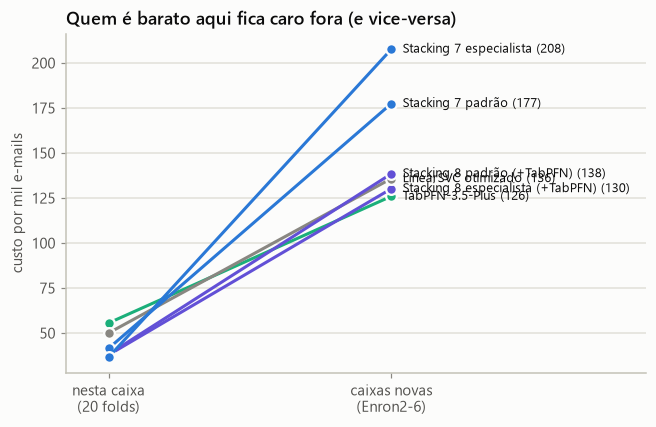

In [3]:
comum = [m for m in t20.index if m in tex.index]
fig, ax = plt.subplots(figsize=(6.8, 4))
for i, mt in enumerate(sorted(comum, key=lambda k: tex.loc[k, "custo_por_mil"])):
    a, b = t20.loc[mt, "custo_por_mil"], tex.loc[mt, "custo_por_mil"]
    cor = graficos.CATEGORICA[6] if "8" in mt else graficos.CATEGORICA[0] if "Stacking 7" in mt else graficos.CATEGORICA[2] if "TabPFN" in mt else graficos.TINTA_MUDA
    ax.plot([0, 1], [a, b], color=cor, marker="o", ms=7, mec=graficos.SUPERFICIE, mew=1.5)
    ax.text(1.04, b, f"{mt} ({b:.0f})", va="center", fontsize=8.5, color=graficos.TINTA)
ax.set_xticks([0, 1], ["nesta caixa\n(20 folds)", "caixas novas\n(Enron2-6)"]); ax.set_xlim(-0.15, 1.9)
ax.set_ylabel("custo por mil e-mails"); ax.grid(axis="x", visible=False)
ax.set_title("Quem é barato aqui fica caro fora (e vice-versa)")
graficos.mostrar(fig, "06_custo_dentro_fora")

**Leitura.**
- **Nesta caixa**, o TabPFN sozinho empata com o melhor modelo único (LinearSVC) e, no stacking, é redundante:
  o Stacking 8 equivale ao Stacking 7.
- **Em caixas novas**, ele é o mais conservador com e-mails reais e baixa o custo do stacking. Esse achado levou
  à decisão pré-registrada D10, testada numa terceira base (script 08).
- **Local × nuvem:** as notas têm correlação de 0,993; o experimento pode ser refeito sem conta e sem internet
  (cerca de 3 h em CPU para 5 divisões).

In [4]:
corr_ln = 0.993   # correlação média das notas local × nuvem (experimento 05, seção 11)
saidas.gravar("06_corrida_tabpfn", {
    "corrida": dict(resumo=corr.reset_index(), decisao="Especialista = configuração do GA do experimento 03 (#5), definida antes da corrida"),
    "tabpfn": dict(versao_nuvem="TabPFN-3.5-Plus", versao_local="TabPFN-3.5-Fast", interno=t20.reset_index(), externo=tex.reset_index(),
                   local_x_nuvem=dict(tabela=tln.reset_index(), correlacao_notas=corr_ln)),
}, fonte="scripts/06_corrida_e_tabpfn.py")
print("gravado: resultados/06_corrida_tabpfn.json")

gravado: resultados/06_corrida_tabpfn.json
